In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# car.data에는 헤더가 없으므로 header=None
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/car.data", header=None)
df.columns = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
print(df.shape)
df.head()

Mounted at /content/drive
(1728, 7)


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [2]:
# 1. 결측치 확인
print(df.isnull().sum())
print("\n전체 결측치 개수 =", df.isnull().sum().sum())

buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

전체 결측치 개수 = 0


class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

class
unacc    0.700
acc      0.222
good     0.040
vgood    0.038
Name: proportion, dtype: float64


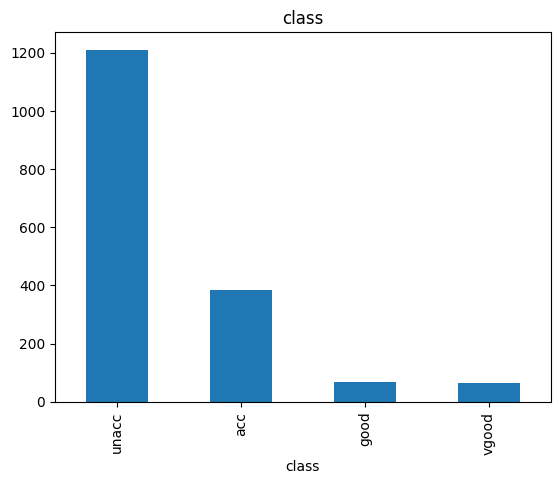

In [3]:
# 2. 레이블 개수 확인
print(df['class'].value_counts())
print()
print(df['class'].value_counts(normalize=True).round(3))

df['class'].value_counts().plot(kind='bar', title='class')
plt.show()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


,buying,maint,doors,persons,lug_boot,safety,class
count,1728,1728,1728,1728,1728,1728,1728
unique,4,4,4,3,3,3,4
top,vhigh,vhigh,2,2,small,low,unacc
freq,432,432,432,576,576,576,1210


buying
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64 

maint
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64 

doors
2        432
3        432
4        432
5more    432
Name: count, dtype: int64 

persons
2       576
4       576
more    576
Name: count, dtype: int64 

lug_boot
small    576
med      576
big      576
Name: count, dtype: int64 

safety
low     576
med     576
high    576
Name: count, dtype: int64 



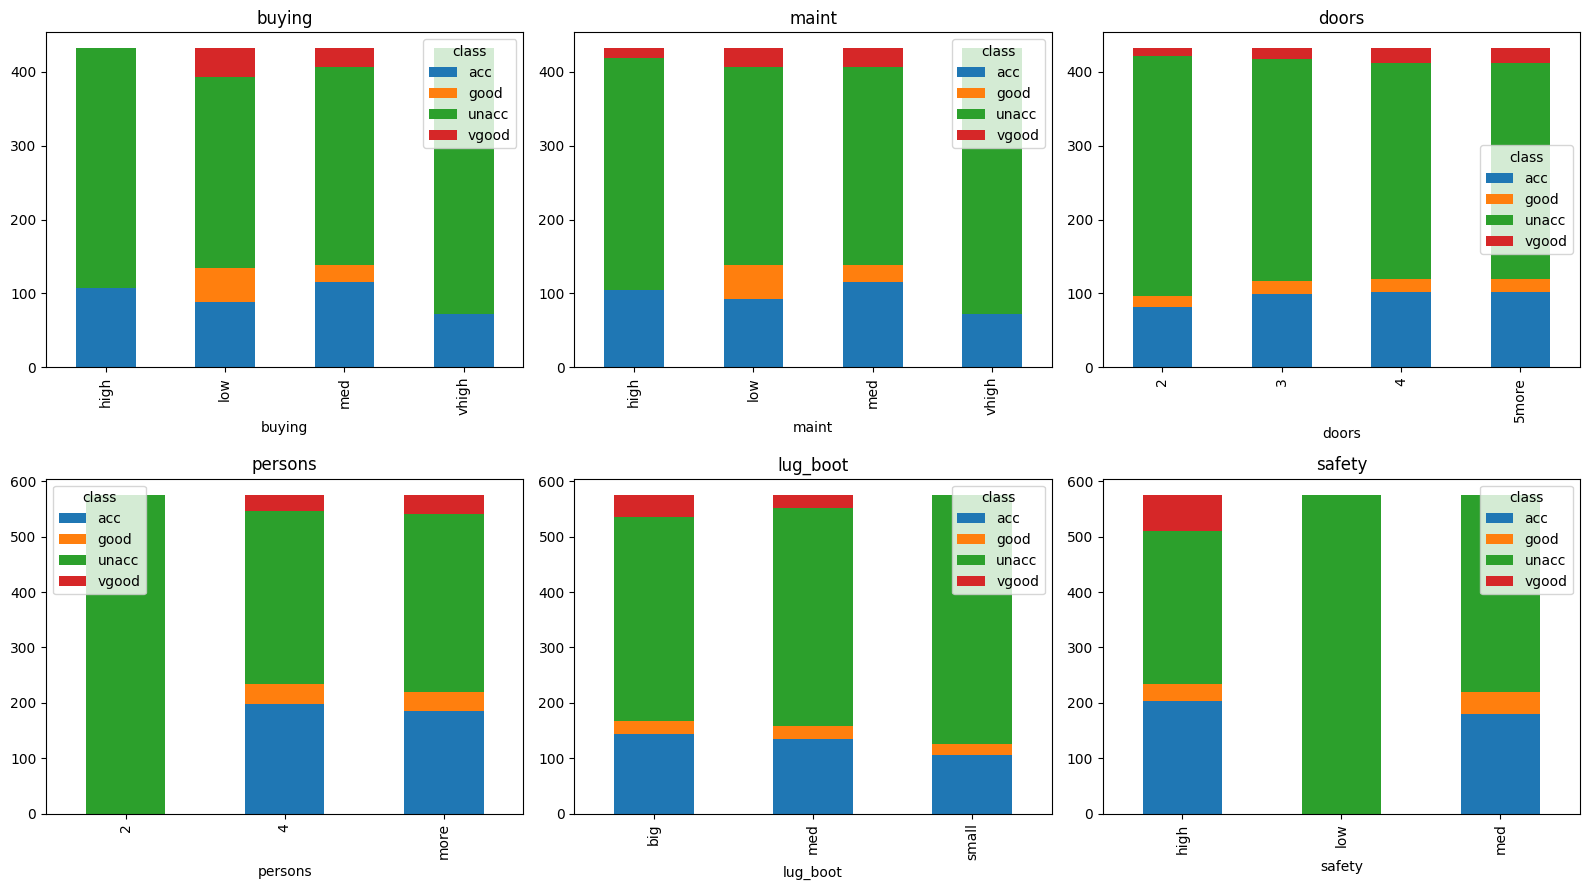

In [4]:
# 3. EDA
df.info()
display(df.describe())

# 모든 변수가 범주형 -> 변수별 값 개수
for col in df.columns.drop('class'):
    print(df[col].value_counts(), '\n')

# 변수별 class 분포
features = df.columns.drop('class')
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), features):
    pd.crosstab(df[col], df['class']).plot(kind='bar', stacked=True, ax=ax, title=col)
plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from sklearn.preprocessing import OrdinalEncoder, LabelEncoder

# 1. 데이터 불러오기
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/car.data")

df.columns = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

X = pd.get_dummies(df.drop(columns=['class'])).values.astype(float)
y = (df['class'] != 'unacc').astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
X

array([[0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       ...,
       [0., 1., 0., ..., 0., 1., 0.],
       [0., 1., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 1., 0., 0.]])

In [ ]:
y

array([0, 0, 0, ..., 0, 1, 1])

In [6]:
model_binary = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(X.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid'),  # 이진 분류용 설정
])

model_binary.compile(
    optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']
)

# 8. 모델 학습
history = model_binary.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2, verbose=1)

# 9. 테스트 데이터 예측
y_prob = model_binary.predict(X_test)
y_pred = (y_prob > 0.5).astype(int).flatten()
y_true = y_test


# 10. 성능 평가
accuracy = accuracy_score(y_true, y_pred)
print("\nAccuracy =", accuracy)
print("\nConfusion Matrix")
print(confusion_matrix(y_true, y_pred))
print("\nClassification Report")
print(classification_report(y_true, y_pred))

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6984 - loss: 0.5963 - val_accuracy: 0.7076 - val_loss: 0.5410
Epoch 2/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7301 - loss: 0.4859 - val_accuracy: 0.7581 - val_loss: 0.4406
Epoch 3/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8333 - loss: 0.3818 - val_accuracy: 0.8917 - val_loss: 0.3326
Epoch 4/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9230 - loss: 0.2833 - val_accuracy: 0.9350 - val_loss: 0.2508
Epoch 5/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9493 - loss: 0.2096 - val_accuracy: 0.9422 - val_loss: 0.1992
Epoch 6/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9583 - loss: 0.1617 - val_accuracy: 0.9422 - val_loss: 0.1701
Epoch 7/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9656 - loss: 0.1322 - val_accuracy: 0.9567 - val_loss: 0.1515
Epoch 8/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9764 - loss: 0.1119 - val_accuracy: 0.9531 - val_loss: 0.1416
Epo

In [7]:
model_multi_single = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(X.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax'),  # 다중 단일정답용 설정
])

model_multi_single.compile(
    optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy']
)

# 다중 단일정답용 y: class 4개를 원핫 인코딩 (열 순서: acc, good, unacc, vgood)
y_df = pd.get_dummies(df['class'])
y_multi_oh = y_df.values.astype(float)

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X, y_multi_oh, test_size=0.2, random_state=42, stratify=df['class']
)

# 8. 모델 학습
history = model_multi_single.fit(X_train_s, y_train_s, epochs=30, batch_size=32, validation_split=0.2, verbose=1)

# 9. 테스트 데이터 예측
y_prob = model_multi_single.predict(X_test_s)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.argmax(y_test_s, axis=1)


# 10. 성능 평가
accuracy = accuracy_score(y_true, y_pred)
print("\nAccuracy =", accuracy)
print("\nConfusion Matrix")
print(confusion_matrix(y_true, y_pred))
print("\nClassification Report")
print(classification_report(y_true, y_pred, target_names=y_df.columns))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.3841 - loss: 1.3525 - val_accuracy: 0.6498 - val_loss: 1.1822
Epoch 2/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6984 - loss: 1.0235 - val_accuracy: 0.6823 - val_loss: 0.9487
Epoch 3/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7047 - loss: 0.8173 - val_accuracy: 0.6823 - val_loss: 0.7924
Epoch 4/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7056 - loss: 0.6859 - val_accuracy: 0.6931 - val_loss: 0.6644
Epoch 5/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7355 - loss: 0.5795 - val_accuracy: 0.7581 - val_loss: 0.5533
Epoch 6/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7908 - loss: 0.4826 - val_accuracy: 0.8195 - val_loss: 0.4614
Epoch 7/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8442 - loss: 0.4054 - val_accuracy: 0.8484 - val_loss: 0.3975
Epoch 8/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8687 - loss: 0.3520 - val_accuracy: 0.8592 - val_loss

In [ ]:
from sklearn.metrics import multilabel_confusion_matrix

model_multi_label = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(X.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(3, activation='sigmoid'),  # 다중 다중정답용 설정
])

model_multi_label.compile(
    optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']
)

# 다중 다중정답용 y: 등급을 3개의 라벨로 표현 (한 행에 1이 여러 개 가능)
# unacc=[0,0,0], acc=[1,0,0], good=[1,1,0], vgood=[1,1,1]
order = {'unacc': 0, 'acc': 1, 'good': 2, 'vgood': 3}
lvl = df['class'].map(order).values
y_ml = np.stack([lvl >= 1, lvl >= 2, lvl >= 3], axis=1).astype(int)
label_names = ['>=acc', '>=good', 'vgood']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X, y_ml, test_size=0.2, random_state=42
)


# 8. 모델 학습
history = model_multi_label.fit(X_train_m, y_train_m, epochs=30, batch_size=32, validation_split=0.2, verbose=1)

# 9. 테스트 데이터 예측
y_prob = model_multi_label.predict(X_test_m)
y_pred = (y_prob > 0.5).astype(int)
y_true = y_test_m


# 10. 성능 평가
accuracy = accuracy_score(y_true, y_pred)  # 3개 라벨이 모두 맞아야 정답
print("\nAccuracy =", accuracy)
print("\nConfusion Matrix (라벨별)")
for name, cm in zip(label_names, multilabel_confusion_matrix(y_true, y_pred)):
    print(name)
    print(cm)
print("\nClassification Report")
print(classification_report(y_true, y_pred, target_names=label_names, zero_division=0))

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.2101 - loss: 0.6162 - val_accuracy: 0.3791 - val_loss: 0.5494
Epoch 2/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6341 - loss: 0.4419 - val_accuracy: 0.8700 - val_loss: 0.3978
Epoch 3/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9629 - loss: 0.3093 - val_accuracy: 0.9964 - val_loss: 0.3358
Epoch 4/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9982 - loss: 0.2571 - val_accuracy: 0.9964 - val_loss: 0.3002
Epoch 5/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9755 - loss: 0.2198 - val_accuracy: 0.9603 - val_loss: 0.2605
Epoch 6/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8986 - loss: 0.1854 - val_accuracy: 0.9134 - val_loss: 0.2219
Epoch 7/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8714 - loss: 0.1555 - val_accuracy: 0.9025 - val_loss: 0.1875
Epoch 8/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8234 - loss: 0.1299 - val_accuracy: 0.8231 - val_loss: 0.1584
Epo